## Eksperimen Praktik Deep Learning (Christella Cindy Wijaya - 2802407742)

### Dataset Oxfors-IIIT Pet


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import json
import random
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

In [ ]:
SEED = 42
BATCH = 32
MAX_EPOCH = 30
PATIENCE = 5
WEIGHT_DECAY = 1e-2

In [ ]:
FOLDER = "/content/drive/MyDrive/Colab Notebooks/Tugas Deep Learning"
os.makedirs(FOLDER, exist_ok=True)

In [ ]:
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"

cuda


In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

### Data Preparation

In [ ]:
# Download dua bagian dataset
pet_trainval = datasets.OxfordIIITPet(root=FOLDER, split="trainval", target_types=("category", "binary-category"), download=True)
pet_test = datasets.OxfordIIITPet(root=FOLDER, split="test", target_types=("category", "binary-category"), download=True)

all_path = pet_trainval._images + pet_test._images
all_label = pet_trainval._labels + pet_test._labels
all_species = pet_trainval._bin_labels + pet_test._bin_labels
print(f'Total gambar: {len(all_path)}')
print(f'Total label: {len(all_label)}')
print(f'Total spesies: {len(all_species)}')
print(f'Jumlah ras: {len(pet_trainval.classes)}')


Total gambar: 7349
Total label: 7349
Total spesies: 7349
Jumlah ras: 37


In [ ]:
id_kucing = sorted({l for l, s in zip(all_label, all_species) if s == 0})
id_anjing = sorted({l for l, s in zip(all_label, all_species) if s == 1})

kelas_kucing = sorted(random.sample(id_kucing, 5))
kelas_anjing = sorted(random.sample(id_anjing, 5))

print(f'Kucing: {kelas_kucing}')
print(f'Anjing: {kelas_anjing}')

Kucing: [0, 5, 20, 26, 33]
Anjing: [1, 3, 12, 13, 24]


In [ ]:
# label baru 0-4 = kucing, 5-9 = anjing
kelas_pilih = kelas_kucing + kelas_anjing
label = {lama: baru for baru, lama in enumerate(kelas_pilih)}
kelas = [pet_trainval.classes[i] for i in kelas_pilih]

# Menyimpan hanya gambar 10 kelas terpilih
path_pilih = [p for p, l in zip(all_path, all_label) if l in label]
label_pilih = [label[l] for l in all_label if l in label]
label_array = np.array(label_pilih)

for baru, nama in enumerate(kelas):
    print(baru, nama, "(kucing)" if baru < 5 else "(anjing)")
print("Jumlah gambar terpilih:", len(path_pilih))

0 Abyssinian (kucing)
1 Bengal (kucing)
2 Maine Coon (kucing)
3 Ragdoll (kucing)
4 Sphynx (kucing)
5 American Bulldog (anjing)
6 Basset Hound (anjing)
7 English Cocker Spaniel (anjing)
8 English Setter (anjing)
9 Pomeranian (anjing)
Jumlah gambar terpilih: 1994


In [ ]:
index = np.arange(len(path_pilih))

idx_train, idx_sisa = train_test_split(index, test_size=0.3, stratify=label_array, random_state=SEED)
idx_val, idx_test = train_test_split(idx_sisa, test_size=0.5, stratify=label_array[idx_sisa], random_state=SEED)

# cegah data leakage
assert len(set(idx_train) & set(idx_val)) == 0
assert len(set(idx_train) & set(idx_test)) == 0
assert len(set(idx_val) & set(idx_test)) == 0

# tabel jumlah gambar per kelas di tiap split
tabel_split = pd.DataFrame({
    "latih": np.bincount(label_array[idx_train], minlength=10), # hitung gambar tiap kelas di data latih
    "val": np.bincount(label_array[idx_val], minlength=10),# hitung gambar tiap kelas di data validasi
    "uji": np.bincount(label_array[idx_test], minlength=10), # hitung gambar tiap kelas di data uji
}, index=kelas)
print(tabel_split)
print("total:", len(idx_train), len(idx_val), len(idx_test))

                        latih  val  uji
Abyssinian                138   30   30
Bengal                    140   30   30
Maine Coon                140   30   30
Ragdoll                   140   30   30
Sphynx                    140   30   30
American Bulldog          140   30   30
Basset Hound              140   30   30
English Cocker Spaniel    137   29   30
English Setter            140   30   30
Pomeranian                140   30   30
total: 1395 299 300


In [ ]:
with open(f'{FOLDER}/config_n_split.json', 'w') as f:
    json.dump({
        "seed": SEED,
        "batch": BATCH,
        "max_epoch": MAX_EPOCH,
        "patience": PATIENCE,
        "weight_decay": WEIGHT_DECAY,
        "gpu": gpu,
        "kelas_terpilih": kelas_pilih,
        "nama_kelas": kelas,
        "idx_train": idx_train.tolist(),
        "idx_val": idx_val.tolist(),
        "idx_test": idx_test.tolist(),
    }, f)

In [ ]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
mean = weights.transforms().mean
std = weights.transforms().std

# transform train data dengan augmentasi
aug_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])
eval_tf = weights.transforms()

In [ ]:
class DataPet(Dataset):
  def __init__(self, path, label, transform):
    self.path = path
    self.label = label
    self.transform = transform

  def __len__(self):
    return len(self.path)

  def __getitem__(self, i):
    gambar = Image.open(self.path[i]).convert('RGB')
    return self.transform(gambar), int(self.label[i])

In [ ]:
path_train = [path_pilih[i] for i in idx_train]; label_train = [label_pilih[i] for i in idx_train]
path_val = [path_pilih[i] for i in idx_val]; label_val = [label_pilih[i] for i in idx_val]
path_test = [path_pilih[i] for i in idx_test]; label_test = [label_pilih[i] for i in idx_test]

data_train_aug = DataPet(path_train, label_train, aug_tf)
data_train_polos = DataPet(path_train, label_train, eval_tf)
data_val = DataPet(path_val, label_val, eval_tf)
data_test = DataPet(path_test, label_test, eval_tf)

gen = torch.Generator()
loader_train_aug = DataLoader(data_train_aug, batch_size=BATCH, shuffle=True, generator=gen, num_workers=2)
loader_train_polos = DataLoader(data_train_polos, batch_size=BATCH, shuffle=True, generator=gen, num_workers=2)
loader_train_eval = DataLoader(data_train_polos, batch_size=BATCH, shuffle=False, num_workers=2)
loader_val = DataLoader(data_val, batch_size=BATCH, shuffle=False, num_workers=2)
loader_test = DataLoader(data_test, batch_size=BATCH, shuffle=False, num_workers=2)

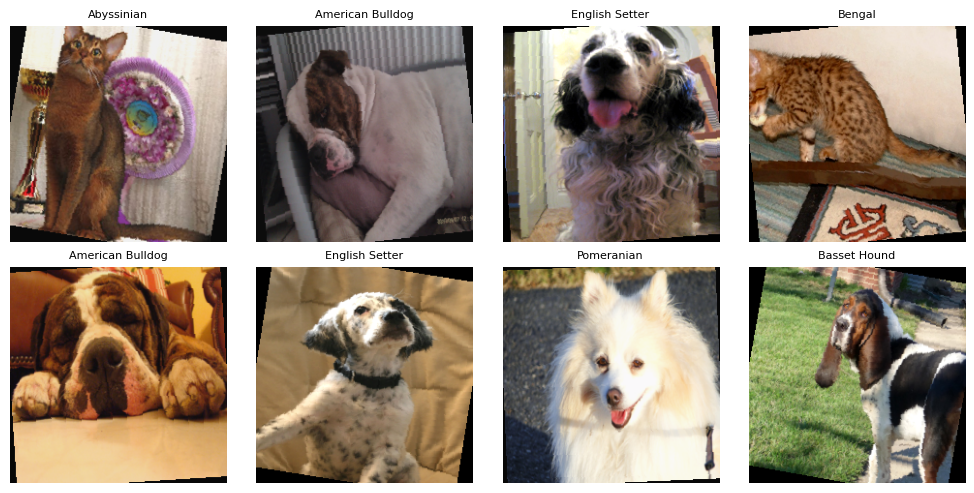

In [ ]:
# cek setelah augmentasi

# ambil 1 batch
gambar_batch, label_batch = next(iter(loader_train_aug))
mean_t = torch.tensor(mean).view(3, 1, 1)
std_t = torch.tensor(std).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for k, ax in enumerate(axes.flatten()):
    # Kembalikan ke normalisasi warna asli
    show = (gambar_batch[k] * std_t + mean_t).clamp(0, 1)
    ax.imshow(show.permute(1, 2, 0))
    ax.set_title(kelas[label_batch[k]], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
loss_fn = nn.CrossEntropyLoss()
hasil = {}
semua_riwayat = {}
semua_prediksi = {}

def evaluasi(model, loader):
    model.eval()
    loss_total, benar, jumlah = 0.0, 0, 0
    daftar_y, daftar_pred, daftar_prob = [], [], []
    with torch.no_grad():
        for gambar, label in loader:
            gambar, label = gambar.to(device), label.to(device)
            output = model(gambar) # hasil mentah model
            loss = loss_fn(output, label)
            prob = torch.softmax(output, dim=1)
            pred = prob.argmax(dim=1) # kelas dengan probabilitas tertinggi
            loss_total += loss.item() * len(label) # jumlahkan loss (dikali ukuran batch)
            benar += (pred == label).sum().item()
            jumlah += len(label)
            daftar_y.append(label.cpu()); daftar_pred.append(pred.cpu()); daftar_prob.append(prob.cpu())
    return (loss_total / jumlah, benar / jumlah,
            torch.cat(daftar_y).numpy(), torch.cat(daftar_pred).numpy(), torch.cat(daftar_prob).numpy())

def train_dan_evaluasi(nama, model, optimizer, loader_train, modul_eval, strategi, augmentasi):
    model.to(device)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad) # jumlah parameter yang ditrain
    total = sum(p.numel() for p in model.parameters())
    lr_grup = [g["lr"] for g in optimizer.param_groups]  # learning rate tiap parameter
    gen.manual_seed(SEED)

    riwayat = []
    loss_best = float('inf')
    bobot_best = None
    epoch_best = 0
    hitung_patience = 0
    start = time.time()

    for epoch in range(1, MAX_EPOCH + 1):
        model.train()
        for m in modul_eval:
            m.eval()
        loss_total, benar, jumlah = 0.0, 0, 0
        for gambar, label in loader_train:
            gambar, label = gambar.to(device), label.to(device)
            optimizer.zero_grad()
            output = model(gambar) # forward: tebak kelas
            loss = loss_fn(output, label)
            loss.backward() # hitung gradien
            optimizer.step() # update bobot yang boleh ditrain
            loss_total += loss.item() * len(label)
            benar += (output.argmax(dim=1) == label).sum().item() # hitung prediksi benar
            jumlah += len(label)
        val_loss, val_acc, _, _, _ = evaluasi(model, loader_val)
        riwayat.append({"epoch": epoch, "train_loss": loss_total / jumlah, "train_acc": benar / jumlah,
                        "val_loss": val_loss, "val_acc": val_acc})

        if val_loss < loss_best:
            loss_best = val_loss
            epoch_best = epoch
            bobot_best = copy.deepcopy(model.state_dict())
            hitung_patience = 0
        else:
            hitung_patience += 1
        if hitung_patience >= PATIENCE:
            print(f"Early stopping pada epoch {epoch}")
            break

    durasi = time.time() - start

    model.load_state_dict(bobot_best)
    torch.save(bobot_best, f'{FOLDER}/{nama}_best.pt')

    _, acc_train_polos, _, _, _ = evaluasi(model, loader_train_eval)
    val_loss, val_acc, _, _, _ = evaluasi(model, loader_val)
    start_test = time.time()
    test_loss, test_acc, y_asli, y_pred, y_prob = evaluasi(model, loader_test)
    waktu_test = time.time() - start_test
    f1_makro = f1_score(y_asli, y_pred, average="macro")

    hasil[nama] = {"eksperimen": nama, "strategi": strategi, "augmentasi": augmentasi,
                   "trainable_params": trainable, "total_params": total, "lr": str(lr_grup),
                   "epoch_terbaik": epoch_best, "epoch_total": epoch,
                   "berhenti_karena": "early stopping" if hitung_patience >= PATIENCE else "batas epoch",
                   "durasi_detik": durasi, "val_loss": val_loss, "val_acc": val_acc,
                   "train_acc_tanpa_aug": acc_train_polos, "gap_train_val": acc_train_polos - val_acc,
                   "test_loss": test_loss, "test_acc": test_acc, "test_f1_makro": f1_makro,
                   "waktu_test_detik": waktu_test, "seed": SEED, "gpu": gpu}

    semua_riwayat[nama] = riwayat
    semua_prediksi[nama] = (y_asli, y_pred, y_prob)

    pd.DataFrame(hasil.values()).to_csv(f"{FOLDER}/hasil_ringkasan.csv", index=False)
    pd.concat([pd.DataFrame(r).assign(eksperimen=n) for n, r in semua_riwayat.items()]).to_csv(f"{FOLDER}/riwayat_epoch.csv", index=False)

    print(f"{nama}: trainable {trainable:,} | epoch best {epoch_best}/{epoch} ({hasil[nama]['berhenti_karena']}) | "
          f"val acc {val_acc:.4f} | test acc {test_acc:.4f} | test F1 {f1_makro:.4f} | durasi {durasi:.0f} dtk")

### B1: ResNet-18 baseline

In [ ]:
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 10)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)
assert sum(p.numel() for p in model.parameters() if p.requires_grad) == 11181642
train_dan_evaluasi("B1_dari_nol", model, optimizer, loader_train_aug, [], "dari nol", "ya")

Early stopping pada epoch 13
B1_dari_nol: trainable 11,181,642 | epoch best 8/13 (early stopping) | val acc 0.3813 | test acc 0.3933 | test F1 0.3666 | durasi 257 dtk


### B2 - Feature Extraction

In [36]:
model = models.resnet18(weights=weights)

for p in model.parameters():
    p.requires_grad = False # bekukan semua parameter
model.fc = nn.Linear(model.fc.in_features, 10) # layer baru

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert trainable == 5130, trainable # 512*10 + 10 = 5130
optimizer = torch.optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)

modul_beku = [model.conv1, model.bn1, model.layer1, model.layer2, model.layer3, model.layer4]
awal = copy.deepcopy(model.layer1.state_dict())

train_dan_evaluasi("B2_feature_extraction", model, optimizer, loader_train_aug, modul_beku, "feature extraction", "ya")

akhir = model.layer1.state_dict()
print("layer1 tidak berubah?", all(torch.equal(awal[k], akhir[k].cpu()) for k in awal))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 175MB/s]


B2_feature_extraction: trainable 5,130 | epoch best 29/30 (batas epoch) | val acc 0.9666 | test acc 0.9633 | test F1 0.9633 | durasi 544 dtk
layer1 tidak berubah? True


### B3 -  Progressive Fine-Tuning

In [37]:
model = models.resnet18(weights=weights)
for p in model.parameters():
    p.requires_grad = False # bekukan semua parameter
model.fc = nn.Linear(model.fc.in_features, 10) # layer baru (trainable)
for p in model.layer4.parameters():
    p.requires_grad = True # buka layer4 biar ikut di train

assert sum(p.numel() for p in model.parameters() if p.requires_grad) == 8398858   # layer4 (8.393.728) + fc (5.130)

optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(), "lr": 1e-3},
], weight_decay=WEIGHT_DECAY)

modul_beku = [model.conv1, model.bn1, model.layer1, model.layer2, model.layer3]
awal = copy.deepcopy(model.layer3.state_dict())

train_dan_evaluasi("B3_finetuning", model, optimizer, loader_train_aug, modul_beku, "fine-tuning layer4 + fc", "ya")

akhir = model.layer3.state_dict()
print("layer3 tidak berubah?", all(torch.equal(awal[k], akhir[k].cpu()) for k in awal))

Early stopping pada epoch 9
B3_finetuning: trainable 8,398,858 | epoch best 4/9 (early stopping) | val acc 0.9632 | test acc 0.9633 | test F1 0.9632 | durasi 149 dtk
layer3 tidak berubah? True


### B4 - Test Augmentasi (Kondisi B3)

In [38]:
model = models.resnet18(weights=weights)
for p in model.parameters():
    p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, 10)
for p in model.layer4.parameters():
    p.requires_grad = True

optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(), "lr": 1e-3},
], weight_decay=WEIGHT_DECAY)

modul_beku = [model.conv1, model.bn1, model.layer1, model.layer2, model.layer3]
train_dan_evaluasi("B4_B3_tanpa_augmentasi", model, optimizer, loader_train_polos, modul_beku, "fine-tuning layer4 + fc", "tidak")

Early stopping pada epoch 20
B4_B3_tanpa_augmentasi: trainable 8,398,858 | epoch best 15/20 (early stopping) | val acc 0.9732 | test acc 0.9667 | test F1 0.9666 | durasi 341 dtk


### B5 - EfficientNet-B0

In [39]:
mode_b5 = "finetuning" if hasil["B3_finetuning"]["val_loss"] < hasil["B2_feature_extraction"]["val_loss"] else "feature_extraction"
print("mode B5:", mode_b5)

mode B5: feature_extraction


In [40]:
bobot_eff = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model = models.efficientnet_b0(weights=bobot_eff)

for p in model.parameters():
    p.requires_grad = False
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 10)

if mode_b5 == "finetuning":
    for p in model.features[7:].parameters():
        p.requires_grad = True
    optimizer = torch.optim.AdamW([
        {"params": model.features[7:].parameters(), "lr": 1e-4},
        {"params": model.classifier.parameters(), "lr": 1e-3},
    ], weight_decay=WEIGHT_DECAY)
    modul_beku = list(model.features[:7])
    strategi = "fine-tuning features[7:] + classifier"

else:
  optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)
  modul_beku = list(model.features)
  strategi = "feature extraction"

train_dan_evaluasi("B5_efficientnet_b0", model, optimizer, loader_train_aug, modul_beku, strategi, "ya")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 143MB/s]


B5_efficientnet_b0: trainable 12,810 | epoch best 27/30 (batas epoch) | val acc 0.9833 | test acc 0.9800 | test F1 0.9801 | durasi 583 dtk


### Tabel Konsolidasi

In [42]:
tabel = pd.DataFrame(hasil.values())
kolom = ["eksperimen", "strategi", "augmentasi", "trainable_params", "lr", "epoch_terbaik", "epoch_total",
         "berhenti_karena", "durasi_detik", "val_acc", "train_acc_tanpa_aug", "gap_train_val",
         "test_acc", "test_f1_makro", "total_params", "waktu_test_detik"]
tabel[kolom].round(4)

,eksperimen,strategi,augmentasi,trainable_params,lr,epoch_terbaik,epoch_total,berhenti_karena,durasi_detik,val_acc,train_acc_tanpa_aug,gap_train_val,test_acc,test_f1_makro,total_params,waktu_test_detik
0,B1_dari_nol,dari nol,ya,11181642,[0.001],8,13,early stopping,256.8168,0.3813,0.4380,0.0567,0.3933,0.3666,11181642,2.2358
1,B2_feature_extraction,feature extraction,ya,5130,[0.001],29,30,batas epoch,544.0639,0.9666,0.9806,0.0141,0.9633,0.9633,11181642,2.2614
2,B3_finetuning,fine-tuning layer4 + fc,ya,8398858,"[0.0001, 0.001]",4,9,early stopping,149.3406,0.9632,0.9935,0.0303,0.9633,0.9632,11181642,2.1516
3,B4_B3_tanpa_augmentasi,fine-tuning layer4 + fc,tidak,8398858,"[0.0001, 0.001]",15,20,early stopping,341.4473,0.9732,1.0000,0.0268,0.9667,0.9666,11181642,2.7235
4,B5_efficientnet_b0,feature extraction,ya,12810,[0.001],27,30,batas epoch,582.9127,0.9833,0.9957,0.0124,0.9800,0.9801,4020358,2.8824


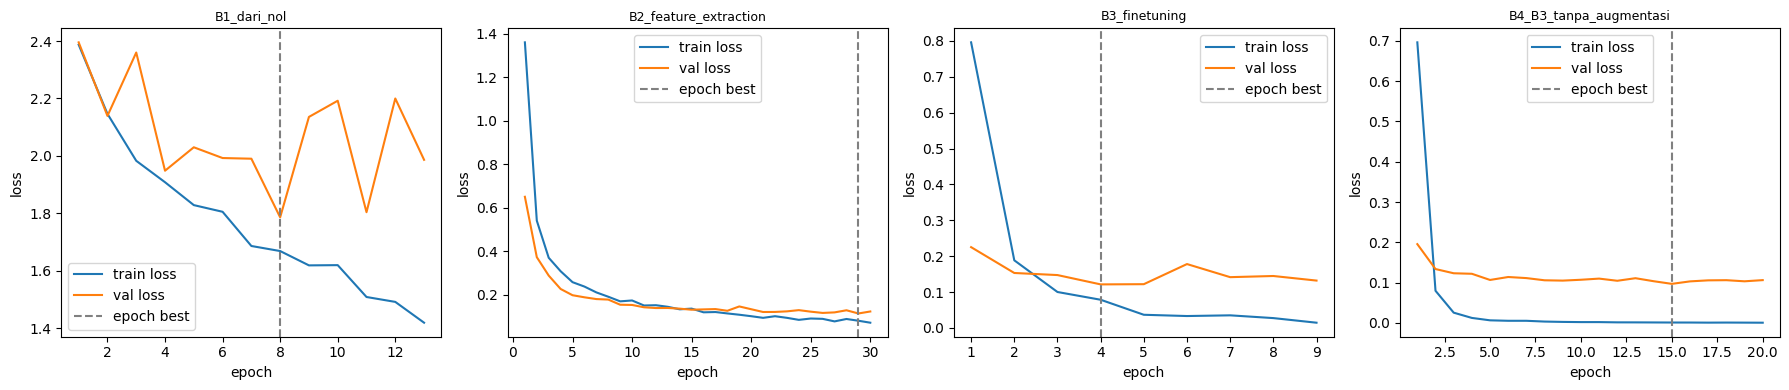

In [44]:
daftar = ["B1_dari_nol", "B2_feature_extraction", "B3_finetuning", "B4_B3_tanpa_augmentasi"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, nama in zip(axes, daftar):
    r = pd.DataFrame(semua_riwayat[nama])
    ax.plot(r["epoch"], r["train_loss"], label="train loss")
    ax.plot(r["epoch"], r["val_loss"], label="val loss")
    ax.axvline(hasil[nama]["epoch_terbaik"], linestyle="--", color="gray", label="epoch best")
    ax.set_title(nama, fontsize=9); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FOLDER}/kurva_loss.png", dpi=150)
plt.show()

In [45]:
# B3 (dengan augmentasi) vs B4 (tanpa augmentasi)
b3, b4 = hasil["B3_finetuning"], hasil["B4_B3_tanpa_augmentasi"]
for k in ["train_acc_tanpa_aug", "val_acc", "gap_train_val", "test_f1_makro"]:
    print(f"{k:22s} dengan aug {b3[k]:.4f} | tanpa aug {b4[k]:.4f} | selisih {b3[k] - b4[k]:+.4f}")

train_acc_tanpa_aug    dengan aug 0.9935 | tanpa aug 1.0000 | selisih -0.0065
val_acc                dengan aug 0.9632 | tanpa aug 0.9732 | selisih -0.0100
gap_train_val          dengan aug 0.0303 | tanpa aug 0.0268 | selisih +0.0036
test_f1_makro          dengan aug 0.9632 | tanpa aug 0.9666 | selisih -0.0034


### Failure Analysis

model best: B5_efficientnet_b0
jumlah salah: 6 dari 300


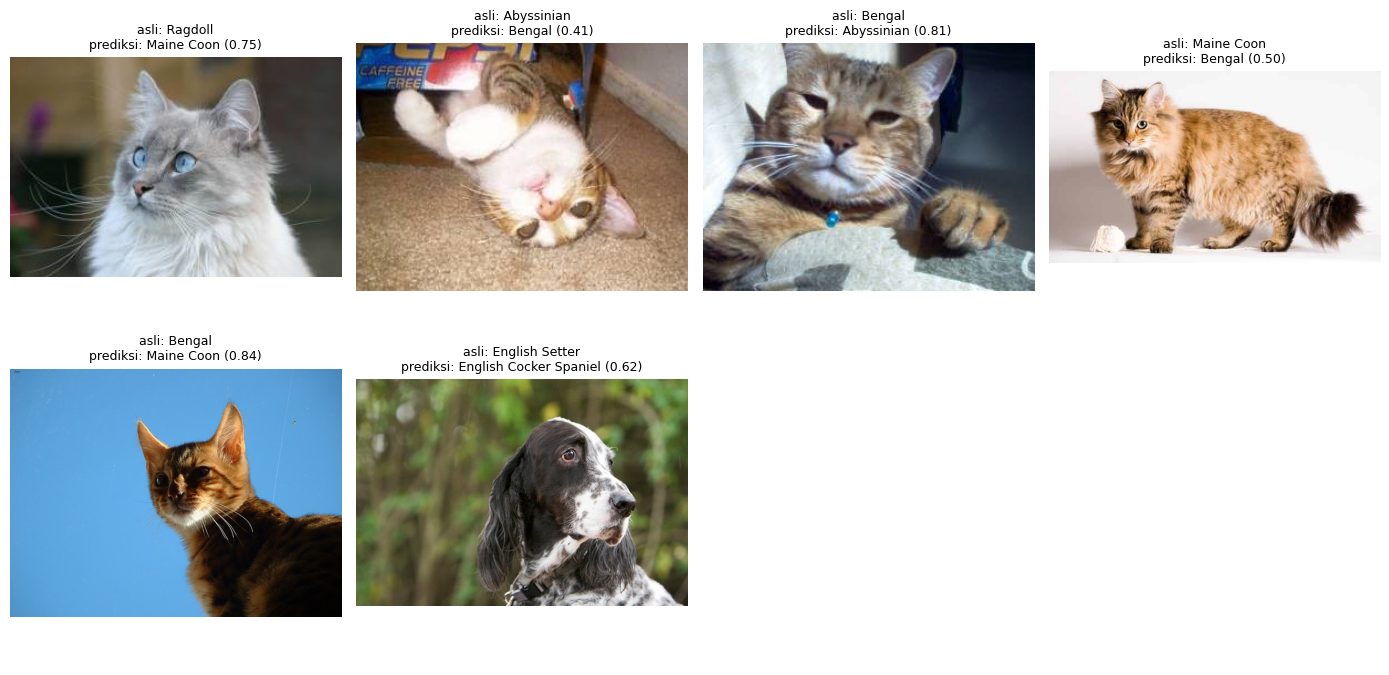

In [48]:
# model best = val loss terendah
nama_best = min(hasil, key=lambda n: hasil[n]["val_loss"])
print("model best:", nama_best)
y_asli, y_pred, y_prob = semua_prediksi[nama_best]
salah = np.where(y_asli != y_pred)[0]
print("jumlah salah:", len(salah), "dari", len(y_asli))

pd.DataFrame({"file": [str(path_test[i]) for i in salah],
              "label_asli": [kelas[y_asli[i]] for i in salah],
              "prediksi": [kelas[y_pred[i]] for i in salah],
              "confidence": [float(y_prob[i, y_pred[i]]) for i in salah]}
             ).to_csv(f"{FOLDER}/kesalahan_test_{nama_best}.csv", index=False)

contoh = random.sample(list(salah), min(8, len(salah)))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flatten():
    ax.axis("off")
for ax, i in zip(axes.flatten(), contoh):
    ax.imshow(Image.open(path_test[i]).convert("RGB"))
    ax.set_title(f"asli: {kelas[y_asli[i]]}\nprediksi: {kelas[y_pred[i]]} ({y_prob[i, y_pred[i]]:.2f})", fontsize=9)
plt.tight_layout()
plt.savefig(f"{FOLDER}/failure_analysis.png", dpi=150)
plt.show()

### Tambahan

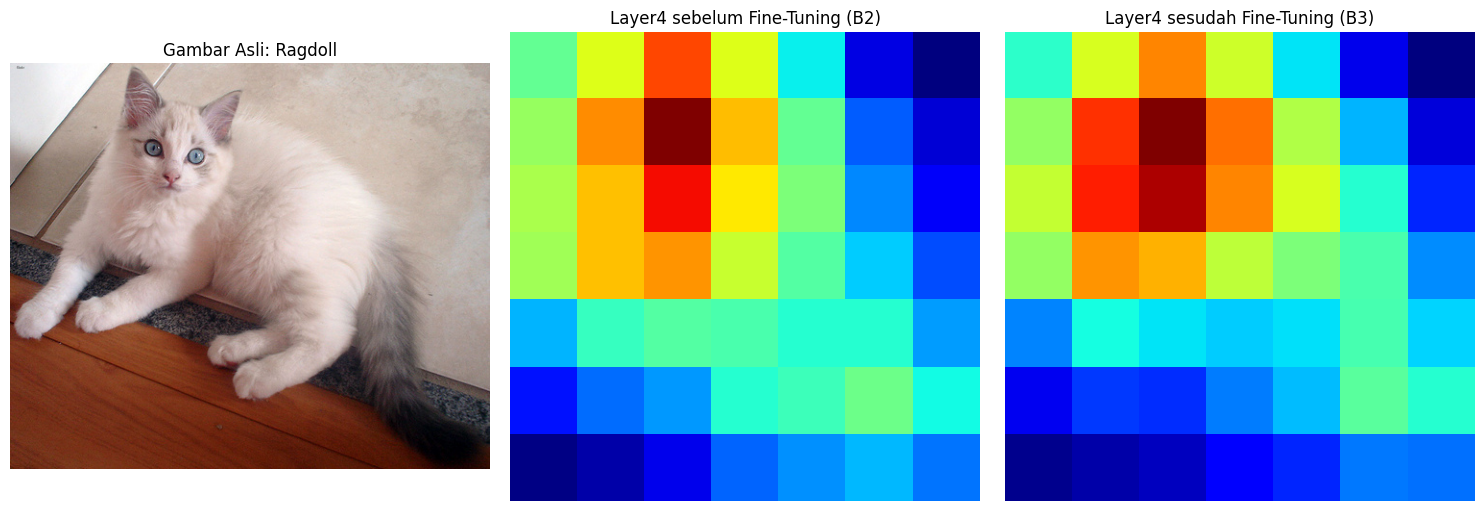

In [49]:
activation = {}
def get_activation(name):
    def hook(model, input, output):
        activation[name] = output.detach()
    return hook

# ambil gambar contoh dari test set
idx_contoh = 0
img_tensor, label_asli = data_test[idx_contoh]
img_tensor = img_tensor.unsqueeze(0).to(device)

# Model sebelum fine tuning (B2)
model_sebelum = models.resnet18(weights=None)
model_sebelum.fc = nn.Linear(model_sebelum.fc.in_features, 10)
model_sebelum.load_state_dict(torch.load(f"{FOLDER}/B2_feature_extraction_best.pt"))
model_sebelum.to(device).eval()

handle_sebelum = model_sebelum.layer4.register_forward_hook(get_activation('sebelum'))
_ = model_sebelum(img_tensor) # Tembak gambar ke model
handle_sebelum.remove()

# Model sesudah fine tuning (B3)
model_sesudah = models.resnet18(weights=None)
model_sesudah.fc = nn.Linear(model_sesudah.fc.in_features, 10)
model_sesudah.load_state_dict(torch.load(f"{FOLDER}/B3_finetuning_best.pt"))
model_sesudah.to(device).eval()
handle_sesudah = model_sesudah.layer4.register_forward_hook(get_activation('sesudah'))
_ = model_sesudah(img_tensor)
handle_sesudah.remove()

map_sebelum = activation['sebelum'].squeeze().mean(dim=0).cpu().numpy()
map_sesudah = activation['sesudah'].squeeze().mean(dim=0).cpu().numpy()

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(Image.open(path_test[idx_contoh]).convert('RGB'))
ax[0].set_title(f"Gambar Asli: {kelas[label_asli]}")
ax[0].axis('off')

ax[1].imshow(map_sebelum, cmap='jet')
ax[1].set_title("Layer4 sebelum Fine-Tuning (B2)")
ax[1].axis('off')

ax[2].imshow(map_sesudah, cmap='jet')
ax[2].set_title("Layer4 sesudah Fine-Tuning (B3)")
ax[2].axis('off')

plt.tight_layout()
plt.savefig(f"{FOLDER}/c5_feature_map.png", dpi=150)
plt.show()